# Lesson 1 · Time-Series Fundamentals
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 13** &nbsp;|&nbsp; ⏱ ≈ 90 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Define a time series and identify its **trend, seasonality, cyclicality and noise**
> - Decompose a series with classical decomposition and STL
> - Explain **stationarity** and test for it (ADF, KPSS); make a series stationary by differencing
> - Compute and interpret **autocorrelation (ACF)** and **partial autocorrelation (PACF)**
> - Create and understand **lag observations**

**Prerequisites:** Lesson 0.

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## 1 · What is a time series?

A **time series** is a set of observations $y_1, y_2, \dots, y_T$ recorded **in time order**, usually at regular intervals.

- **Univariate**: one variable over time (maize price).
- **Multivariate**: several variables over time (price, rainfall, fuel).
- **Frequency**: how often we observe (daily, weekly, monthly, yearly). Our market data is *weekly*.
- **Horizon**: how far ahead we want to forecast ($h = 1$ week, $h = 12$ weeks, …).

> 💡 **Analogy:** a time series is a *film*, not a *photograph*. A single frame (one row) says little; the *motion* between frames is the story.

## 2 · The four ingredients: Trend, Seasonality, Cycles, Noise

Think of a time series as a **smoothie**. Our job is to figure out the ingredients.

| Ingredient | What it is | Agricultural example |
|---|---|---|
| **Trend** $T_t$ | Long-run direction | Prices creeping up with inflation |
| **Seasonality** $S_t$ | Repeating pattern with a **fixed, known period** | Cheaper after each harvest, dearer in the lean season (period = 1 year) |
| **Cyclicality** $C_t$ | Rises and falls with **no fixed period** | Multi-year boom–bust of planting decisions; droughts |
| **Noise** $\varepsilon_t$ | What's left; unpredictable | Random daily trading quirks |

Two ways they combine:

- **Additive:** $y_t = T_t + S_t + C_t + \varepsilon_t$: seasonal swings have constant *size*.
- **Multiplicative:** $y_t = T_t \times S_t \times C_t \times \varepsilon_t$: seasonal swings *grow with the level* (a 10% harvest dip is bigger in absolute terms when prices are high).

Taking logs turns multiplicative into additive: $\log y_t = \log T_t + \log S_t + \dots$ That's why we so often model **log prices**.

### 🔬 Build a series from scratch

The best way to understand ingredients is to *cook the smoothie yourself*:

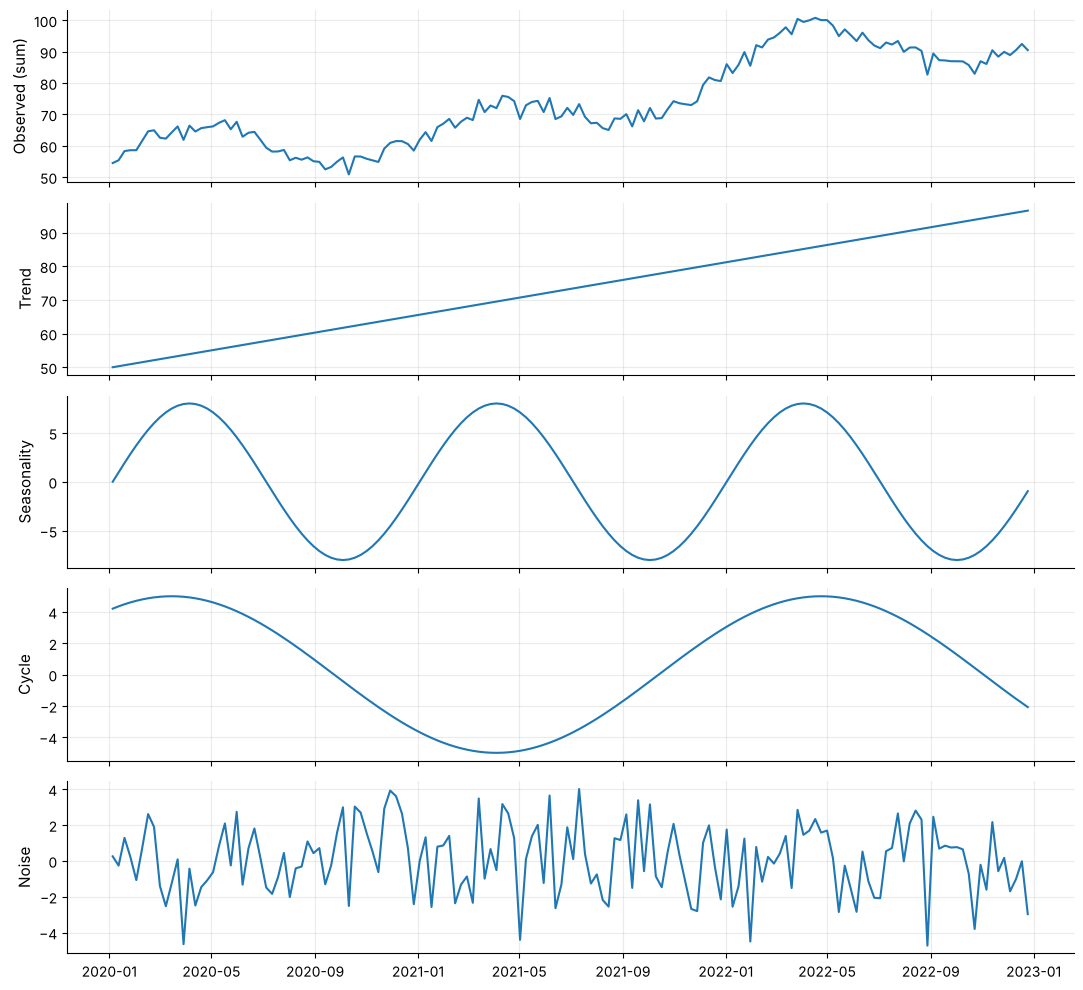

In [2]:
rng = np.random.default_rng(0)
n = 156                                              # 3 years of weekly data
idx = pd.date_range("2020-01-05", periods=n, freq="W-SUN")
t = np.arange(n)

trend  = 50 + 0.30 * t                               # steady climb
season = 8 * np.sin(2 * np.pi * t / 52)              # yearly wave (period 52 weeks)
cycle  = 5 * np.sin(2 * np.pi * t / 110 + 1.0)       # slow wave that is NOT tied to the calendar
noise  = rng.normal(0, 2, n)

y = pd.Series(trend + season + cycle + noise, index=idx)

fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True)
for ax, (name, comp) in zip(axes, [("Observed (sum)", y), ("Trend", trend), ("Seasonality", season), ("Cycle", cycle), ("Noise", noise)]):
    ax.plot(idx, comp, lw=1.5); ax.set_ylabel(name)
plt.tight_layout(); plt.show()

✋ **Pause and think.** Looking only at the top panel (the observed series), could you tell the seasonal wave from the cycle? Not easily, and that is exactly why we need *decomposition*.

## 3 · Decomposition: un-baking the cake

`statsmodels` offers two main tools:
1. **Classical decomposition** (`seasonal_decompose`): simple moving-average based; the seasonal pattern is forced to repeat identically every year.
2. **STL** (Seasonal-Trend decomposition using LOESS): modern, robust to outliers, lets the seasonal shape *evolve*. **Prefer STL in practice.**

Let's decompose real-looking market data: weekly maize, using logs (multiplicative → additive).

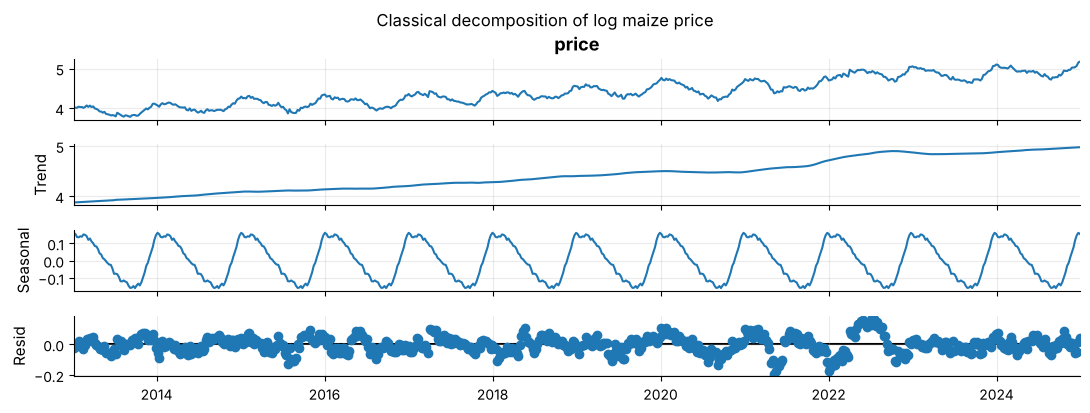

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL

maize = load_weekly("maize")["price"]
logm  = np.log(maize)

# --- classical ---
classical = seasonal_decompose(logm, model="additive", period=52, extrapolate_trend="freq")
classical.plot(); plt.suptitle("Classical decomposition of log maize price", y=1.02); plt.show()

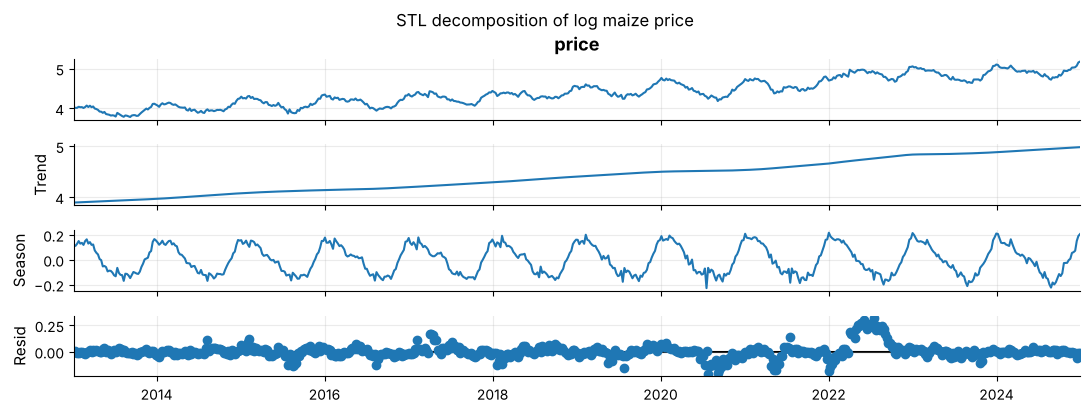

In [4]:
# --- STL (robust) ---
stl = STL(logm, period=52, robust=True).fit()
stl.plot(); plt.suptitle("STL decomposition of log maize price", y=1.02); plt.show()

### Reading the decomposition
- **Trend panel**: slowly rising, with bumps in 2017 and 2022: those are the **droughts** hidden in the simulation.
- **Seasonal panel**: a clean annual wave. On the log scale it swings roughly ±0.2, i.e. about **±15–20 %** around the trend.
- **Residual panel**: should look like noise. If you still see patterns here, the decomposition (or the model!) missed something.

### 📏 How *strong* is the seasonality?
A widely used measure (Hyndman & Athanasopoulos):

$$F_S = \max\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)$$

Values near 1 → strongly seasonal; near 0 → barely seasonal.

Seasonal strength: 0.76   Trend strength: 0.96


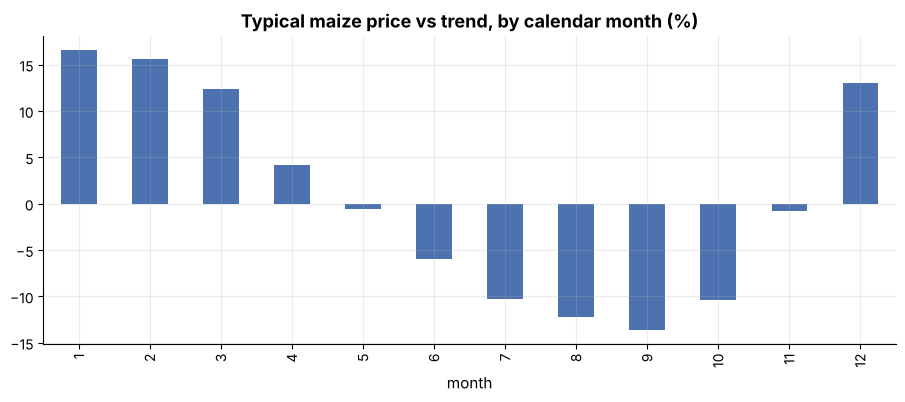

In [5]:
Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"Seasonal strength: {Fs:.2f}   Trend strength: {Ft:.2f}")

# Average shape of the season: which calendar months are cheap / dear (in % vs trend)?
seasonal_by_month = (np.exp(stl.seasonal).groupby(stl.seasonal.index.month).mean() - 1) * 100
seasonal_by_month.round(1).plot.bar(color="#4C72B0", title="Typical maize price vs trend, by calendar month (%)")
plt.xlabel("month"); plt.show()

> 💡 **Business insight:** this bar chart is *money*. Maize sits roughly 10–14 % **below** trend in the harvest months (July–October) and 13–17 % **above** it in the lean season (December–March). A trader can buy low, store, and sell high: until storage costs eat the margin.

## 4 · Seasonality vs cyclicality (a classic exam question)

| | Seasonality | Cyclicality |
|---|---|---|
| Period | **Fixed**, known (52 weeks, 12 months, 7 days) | **Variable**, unknown |
| Cause | Calendar (weather, holidays) | Economics, boom–bust dynamics, solar activity |
| Predictable timing? | Yes | Only roughly |

The real **sunspot** series is the textbook cycle: it peaks roughly every 11 years, but sometimes 9, sometimes 14.

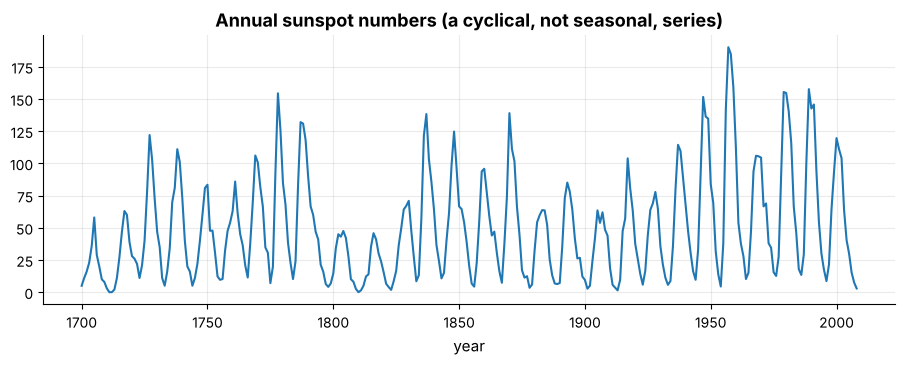

In [6]:
sun = pd.read_csv(DATA / "sunspots_annual.csv").set_index("year")["sunspots"]
sun.plot(title="Annual sunspot numbers (a cyclical, not seasonal, series)", figsize=(11, 3.5)); plt.show()

## 5 · Stationarity: the most important word in time-series statistics

A series is **(weakly) stationary** if its statistical behaviour doesn't depend on *when* you look:
1. constant **mean**,
2. constant **variance**,
3. autocovariance that depends only on the **lag**, not on time.

**Why do we care?** Most classical models (ARMA, ARIMA) *learn* a fixed set of statistical rules from the past and assume the future obeys the same rules.
If the mean keeps drifting, "the rules" keep changing: the model learns nothing stable.

> 💡 **Analogy:** A stationary series is like a drunk person staggering *around a lamppost*: wandering, but always pulled back.
> A non-stationary random walk is a drunk person with *no lamppost*: he can wander arbitrarily far.

Let's *see* four archetypes:

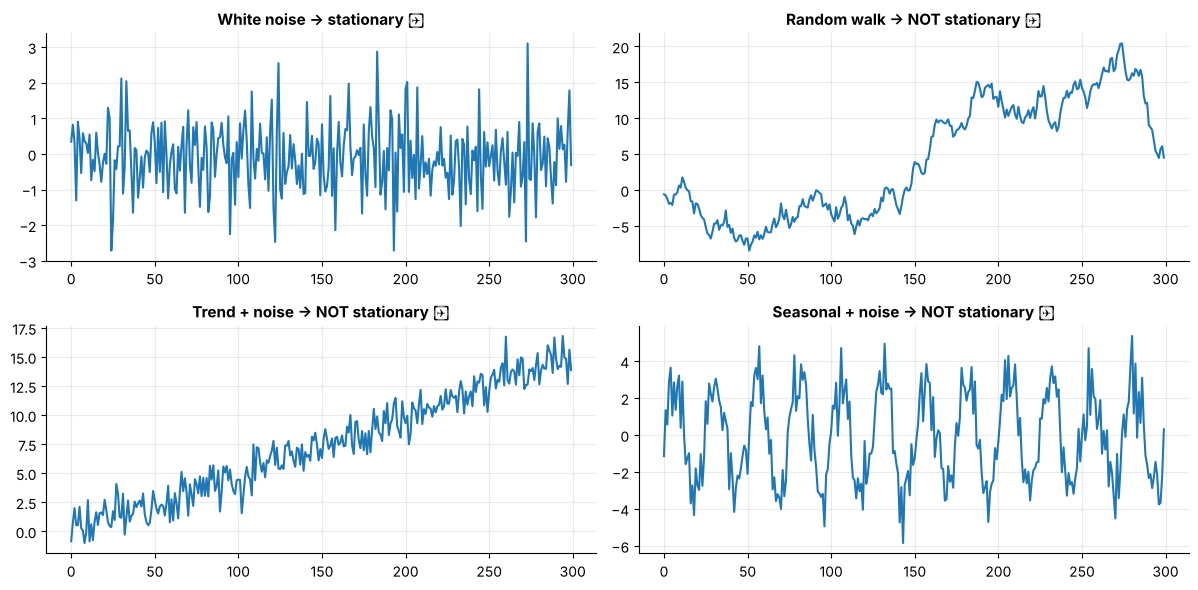

In [7]:
rng = np.random.default_rng(1)
n = 300
white   = rng.normal(0, 1, n)
rw      = np.cumsum(rng.normal(0, 1, n))                       # random walk (unit root)
trendy  = 0.05 * np.arange(n) + rng.normal(0, 1, n)            # trend + noise (trend-stationary)
seasonal_ = 3 * np.sin(2 * np.pi * np.arange(n) / 25) + rng.normal(0, 1, n)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (title, x) in zip(axes.ravel(), [("White noise → stationary ✅", white), ("Random walk → NOT stationary ❌", rw),
                                         ("Trend + noise → NOT stationary ❌", trendy), ("Seasonal + noise → NOT stationary ❌", seasonal_)]):
    ax.plot(x); ax.set_title(title, fontsize=11)
plt.tight_layout(); plt.show()

### Testing for stationarity: ADF and KPSS

Two famous tests with **opposite null hypotheses**: a source of endless student confusion, so memorise this:

| Test | Null hypothesis $H_0$ | Small p-value (< 0.05) means… |
|---|---|---|
| **ADF** (Augmented Dickey-Fuller) | series has a **unit root** (non-stationary) | reject $H_0$ → **likely stationary** ✅ |
| **KPSS** | series **is stationary** | reject $H_0$ → **likely non-stationary** ❌ |

We'll write small wrappers that print a plain-English verdict.

In [8]:
from statsmodels.tsa.stattools import adfuller, kpss

def adf_report(x, name="series"):
    x = pd.Series(x).dropna()
    stat, p, *_ = adfuller(x, autolag="AIC")
    verdict = "stationary ✅ (reject unit root)" if p < 0.05 else "NON-stationary ❌ (cannot reject unit root)"
    print(f"ADF  | {name:<28} | stat={stat:7.2f}  p={p:.4f} | {verdict}")

def kpss_report(x, name="series"):
    x = pd.Series(x).dropna()
    with warnings.catch_warnings():                 # KPSS p-values are capped at 0.01 / 0.10 (lookup table)
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(x, regression="c", nlags="auto")
    verdict = "stationary ✅ (cannot reject)" if p > 0.05 else "NON-stationary ❌ (reject stationarity)"
    print(f"KPSS | {name:<28} | stat={stat:7.2f}  p={p:.4f} | {verdict}")

for name, x in [("white noise", white), ("random walk", rw), ("trend + noise", trendy)]:
    adf_report(x, name); kpss_report(x, name)

ADF  | white noise                  | stat=  -7.24  p=0.0000 | stationary ✅ (reject unit root)
KPSS | white noise                  | stat=   0.13  p=0.1000 | stationary ✅ (cannot reject)
ADF  | random walk                  | stat=  -1.12  p=0.7074 | NON-stationary ❌ (cannot reject unit root)
KPSS | random walk                  | stat=   2.38  p=0.0100 | NON-stationary ❌ (reject stationarity)
ADF  | trend + noise                | stat=  -0.38  p=0.9128 | NON-stationary ❌ (cannot reject unit root)
KPSS | trend + noise                | stat=   2.81  p=0.0100 | NON-stationary ❌ (reject stationarity)


### Making a series stationary: **differencing** (and logs)

If prices wander like a random walk, look at the **changes** instead:

$$\Delta y_t = y_t - y_{t-1}$$

For prices, the **log difference** $\log y_t - \log y_{t-1}$ is the (approximate) **percentage return**: and typically *is* stationary.
Seasonal differencing $y_t - y_{t-m}$ removes a fixed seasonal pattern of period $m$.

Let's apply the full recipe to maize.

ADF  | price (level)                | stat=  -1.16  p=0.6923 | NON-stationary ❌ (cannot reject unit root)
KPSS | price (level)                | stat=   3.28  p=0.0100 | NON-stationary ❌ (reject stationarity)
ADF  | log price                    | stat=  -1.65  p=0.4594 | NON-stationary ❌ (cannot reject unit root)
KPSS | log price                    | stat=   3.39  p=0.0100 | NON-stationary ❌ (reject stationarity)
ADF  | weekly log change (returns)  | stat=  -6.47  p=0.0000 | stationary ✅ (reject unit root)
KPSS | weekly log change (returns)  | stat=   0.03  p=0.1000 | stationary ✅ (cannot reject)
ADF  | 52-week seasonal difference  | stat=  -4.38  p=0.0003 | stationary ✅ (reject unit root)
KPSS | 52-week seasonal difference  | stat=   0.09  p=0.1000 | stationary ✅ (cannot reject)


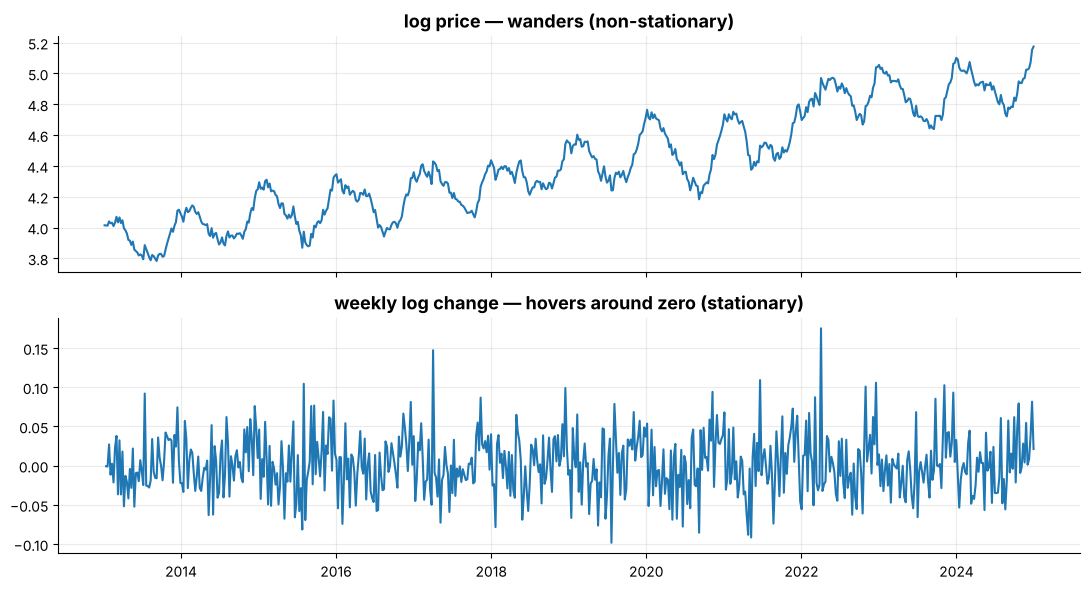

In [9]:
candidates = {
    "price (level)":                 maize,
    "log price":                     np.log(maize),
    "weekly log change (returns)":   np.log(maize).diff(),
    "52-week seasonal difference":   np.log(maize).diff(52),
}
for name, x in candidates.items():
    adf_report(x, name); kpss_report(x, name)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(np.log(maize)); axes[0].set_title("log price: wanders (non-stationary)")
axes[1].plot(np.log(maize).diff()); axes[1].set_title("weekly log change: hovers around zero (stationary)")
plt.tight_layout(); plt.show()

> ⚠️ **Common mistake: over-differencing.** Differencing a series that is already stationary *adds* artificial negative autocorrelation and inflates variance.
> Difference **only as much as needed** (usually $d \le 1$ for prices, plus at most one seasonal difference).

## 6 · Lag observations & autocorrelation

A **lag** is simply a past value of the series: $y_{t-1}$ is the lag-1 value, $y_{t-52}$ the lag-52 value.
*Autocorrelation* measures how strongly the series correlates with its own lags:

$$\rho_k = \operatorname{Corr}(y_t,\, y_{t-k})$$

### 🔍 See it: the lag plot
Each dot is $(y_{t-k}, y_t)$. A tight diagonal line means *the past predicts the present*.

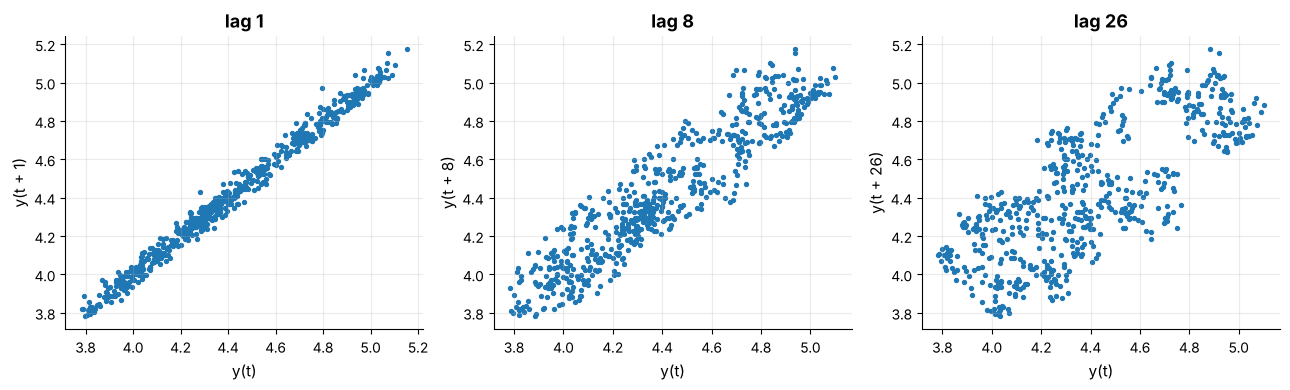

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, k in zip(axes, [1, 8, 26]):
    pd.plotting.lag_plot(np.log(maize), lag=k, ax=ax, s=8); ax.set_title(f"lag {k}")
plt.tight_layout(); plt.show()

### ACF: the *Autocorrelation Function*
The ACF plots $\rho_k$ for $k = 0, 1, 2, \dots$. The shaded band is a 95% confidence region: bars **outside** it are statistically significant.

### PACF: the *Partial Autocorrelation Function*
$\rho_k$ mixes **direct** and **indirect** influence: if Monday affects Tuesday and Tuesday affects Wednesday, then Monday *appears* to affect Wednesday even without a direct link.
The **partial** autocorrelation at lag $k$ removes the influence of the lags in between and shows only the **direct** effect of lag $k$.

> 💡 **Analogy:** Gossip chain. ACF = "how much does Ann's rumour reach Cara?" (including through Ben). PACF = "does Ann tell Cara *directly*, ignoring Ben?"

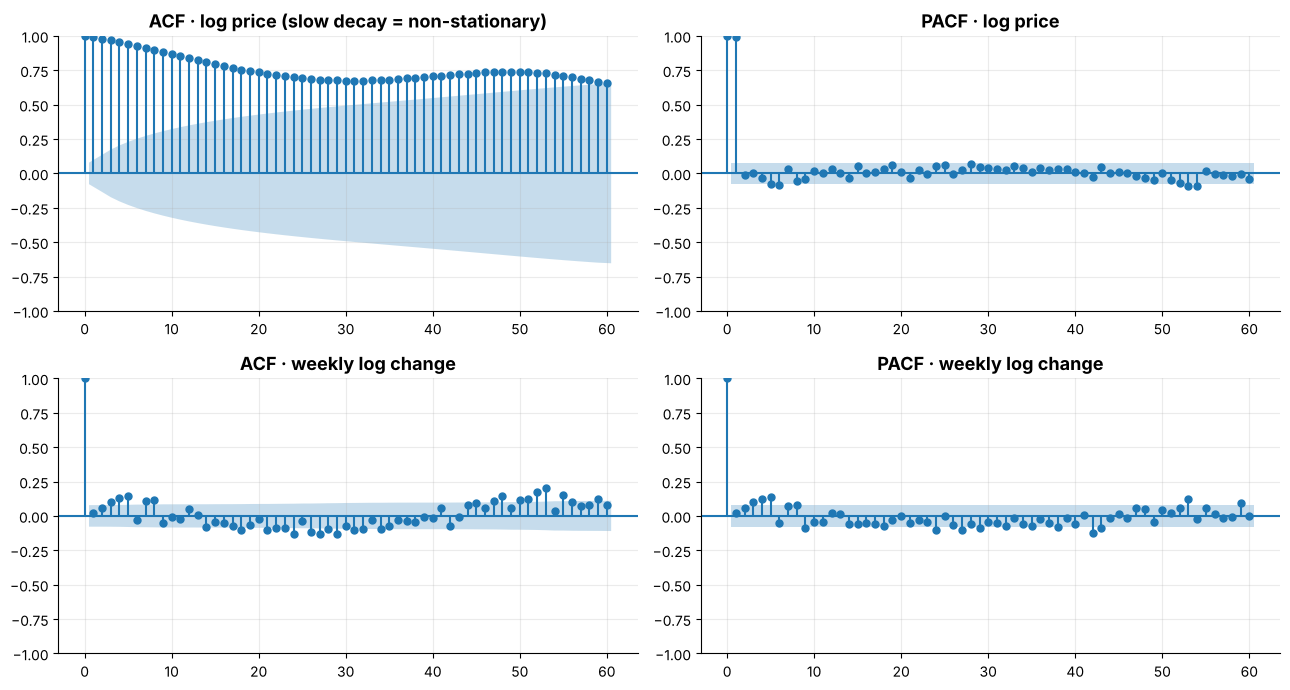

In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(np.log(maize),          lags=60, ax=axes[0, 0], title="ACF · log price (slow decay = non-stationary)")
plot_pacf(np.log(maize),         lags=60, ax=axes[0, 1], title="PACF · log price", method="ywm")
plot_acf(np.log(maize).diff().dropna(),  lags=60, ax=axes[1, 0], title="ACF · weekly log change")
plot_pacf(np.log(maize).diff().dropna(), lags=60, ax=axes[1, 1], title="PACF · weekly log change", method="ywm")
plt.tight_layout(); plt.show()

### 🩺 Reading ACF/PACF patterns (memorise this table: it drives ARIMA in Lesson 5)

| Pattern | ACF | PACF | Suggests |
|---|---|---|---|
| Non-stationary / trending | decays *very slowly*, stays near 1 | one huge spike at lag 1 | difference the series |
| **AR(p)** | decays (geometrically or sine-wave) | **cuts off after lag p** | autoregressive order p |
| **MA(q)** | **cuts off after lag q** | decays | moving-average order q |
| ARMA(p, q) | decays | decays | mixed |
| Seasonal (period m) | spikes at lags m, 2m, … | spikes at m, … | seasonal terms |

Let's *verify* the table with simulated processes where we know the truth:

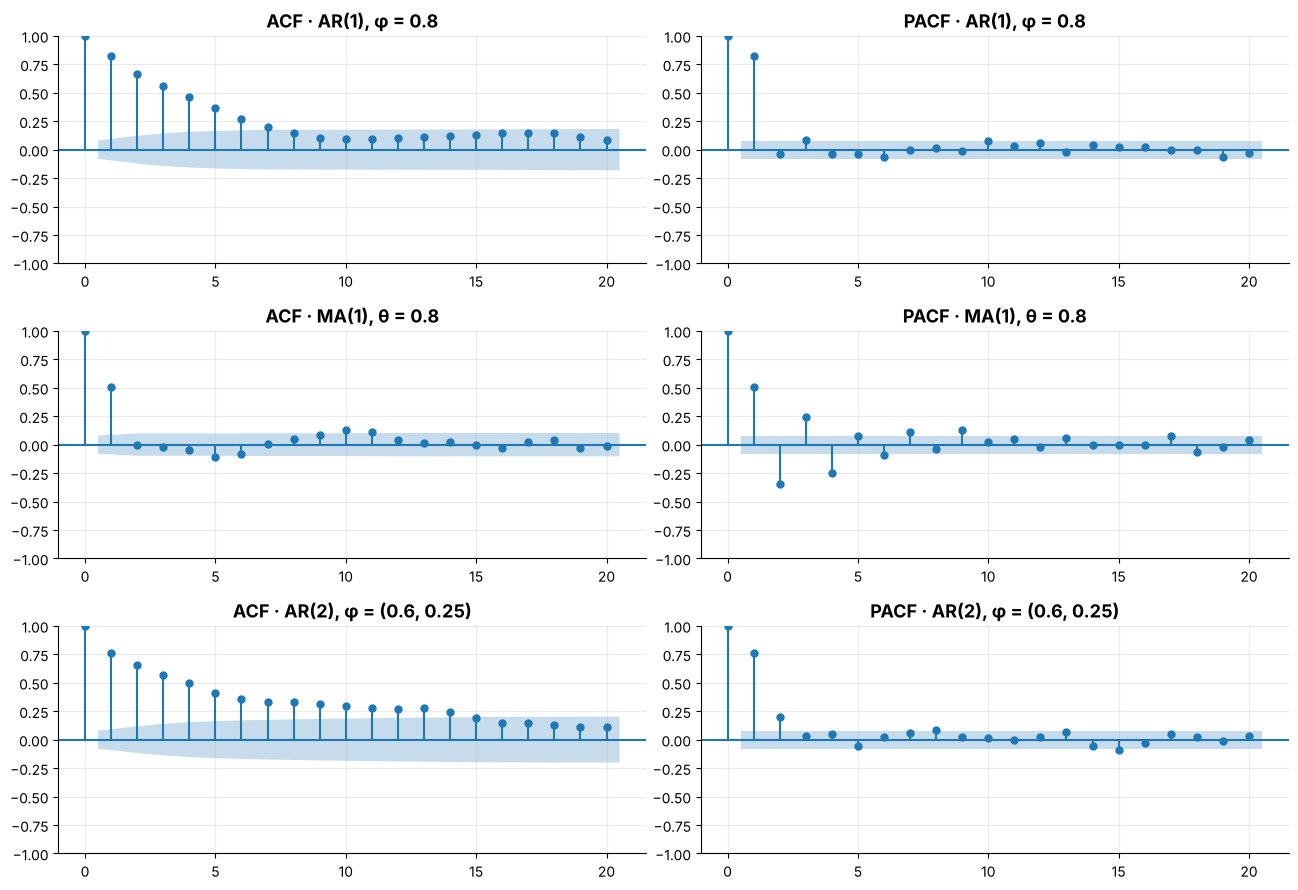

In [12]:
from statsmodels.tsa.arima_process import ArmaProcess
rng = np.random.default_rng(5)
gen = lambda ar, ma: pd.Series(ArmaProcess(ar, ma).generate_sample(600, distrvs=lambda size: rng.standard_normal(size)))
# NOTE statsmodels convention: ar=[1, -phi1, -phi2], ma=[1, theta1]
examples = {"AR(1), φ = 0.8": gen([1, -0.8], [1]),
            "MA(1), θ = 0.8": gen([1], [1, 0.8]),
            "AR(2), φ = (0.6, 0.25)": gen([1, -0.6, -0.25], [1])}

fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for row, (name, s) in zip(axes, examples.items()):
    plot_acf(s, lags=20, ax=row[0], title=f"ACF · {name}")
    plot_pacf(s, lags=20, ax=row[1], title=f"PACF · {name}", method="ywm")
plt.tight_layout(); plt.show()

### 📌 Stationarity, autocorrelation and forecasting: how they connect
- **Autocorrelation is what makes forecasting possible.** If $y_t$ were independent of its past, nothing could be learnt from history.
- **Stationarity makes learning stable.** We estimate relationships from the past and assume they hold in the future.
- **ACF/PACF are your diagnostic X-rays** for choosing a model (Lesson 5) and for checking that a model's *residuals* contain no leftover signal.

## 🧩 Practice problems

### 🧩 Problem 1.1 · Which crop is most seasonal?  ·  🟢 Easy

For each of the four commodities, decompose the **log price** with `STL(period=52, robust=True)` and compute the
  **seasonal strength** `max(0, 1 - Var(residual) / Var(seasonal + residual))` (the formula from the worked example).
  Print the four strengths from strongest to weakest.

<details><summary>💡 Hint 1</summary>

Loop over `['maize','tomato','onion','rice']` and call `load_weekly(name)['price']` inside the loop.

</details>

<details><summary>💡 Hint 2</summary>

`res = STL(np.log(series), period=52, robust=True).fit()` gives `res.seasonal`, `res.resid`, `res.trend`.

</details>

<details><summary>💡 Hint 3</summary>

Strength = `max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())`. Collect into a dict, then `pd.Series(d).sort_values(ascending=False)`.

</details>

In [13]:
from statsmodels.tsa.seasonal import STL
# YOUR CODE HERE

### 🧩 Problem 1.2 · Is tomato stationary?  ·  🟡 Medium

Use the helpers `adf_report` and `kpss_report` (defined in the worked example) to test the **tomato price level** and the **weekly log change** of tomato prices.
  Does tomato need differencing? Then compute the lag-1 autocorrelation of the differenced series and explain (in a comment) why differencing might be a *mistake* here.

<details><summary>💡 Hint 1</summary>

Reminder: ADF's null hypothesis is *'there is a unit root (non-stationary)'*. A small p-value (< 0.05) lets you reject it.

</details>

<details><summary>💡 Hint 2</summary>

Weekly log change: `np.log(s).diff().dropna()`.

</details>

<details><summary>💡 Hint 3</summary>

Remember to also look at the plot of each series: tests can disagree with your eyes when there is strong seasonality.

</details>

<details><summary>💡 Hint 4</summary>

Over-differencing signature: the differenced series has a clearly **negative** lag-1 autocorrelation. Use `acf(x, nlags=1)[1]`.

</details>

In [14]:
tomato = load_weekly('tomato')['price']
# YOUR CODE HERE

### 🧩 Problem 1.3 · Autocorrelation by hand  ·  🟡 Medium

Without using `acf()`, compute the **lag-1, lag-4 and lag-52 autocorrelation** of the **weekly log change** of maize prices
  using `np.corrcoef`. Then confirm with `statsmodels.tsa.stattools.acf`. Store the lag-1 value in `lag1`.

<details><summary>💡 Hint 1</summary>

Autocorrelation at lag k = correlation between the series and itself shifted by k: `np.corrcoef(x[k:], x[:-k])[0, 1]`.

</details>

<details><summary>💡 Hint 2</summary>

`x = np.log(maize['price']).diff().dropna().values`

</details>

<details><summary>💡 Hint 3</summary>

`acf(x, nlags=52)[k]` returns the same idea (tiny differences are normal: statsmodels uses a slightly different normalisation).

</details>

In [15]:
from statsmodels.tsa.stattools import acf
lag1 = None
# YOUR CODE HERE

### 🧩 Problem 1.4 · Mystery process  ·  🟡 Medium

The function below produces a mystery series. **Without looking at the code inside**, use ACF and PACF plots to decide whether it is
  AR(1), AR(2), MA(1) or white noise, and estimate its main coefficient.

<details><summary>💡 Hint 1</summary>

Draw `plot_acf` and `plot_pacf` (30 lags). Which one *cuts off* sharply and which one *decays*?

</details>

<details><summary>💡 Hint 2</summary>

Cheat sheet: AR(p) → PACF cuts off after lag p, ACF decays. MA(q) → ACF cuts off after lag q, PACF decays.

</details>

<details><summary>💡 Hint 3</summary>

For AR(1) the PACF value at lag 1 is (approximately) the coefficient φ.

</details>

In [16]:
from statsmodels.tsa.arima_process import ArmaProcess
def mystery(n=600, seed=11):
    rng = np.random.default_rng(seed)
    return pd.Series(ArmaProcess(ar=[1, -0.7, 0.0], ma=[1]).generate_sample(n, distrvs=lambda size: rng.standard_normal(size)))
m = mystery()
# YOUR CODE HERE

### 🧩 Problem 1.5 · Find the solar cycle  ·  🔴 Challenge

`load_sunspots()` below returns the annual sunspot counts from 1700 onwards. Astronomers say there is a ~11-year solar cycle.
  Use autocorrelation (**not** a plot you eyeball) to estimate the cycle length in years (you should land around 10–11). Is this *seasonality* or *cyclicality*? Why?

<details><summary>💡 Hint 1</summary>

`acf(s, nlags=40)`: a cycle shows up as a bump in the ACF at the cycle length.

</details>

<details><summary>💡 Hint 2</summary>

Search for the biggest ACF value among lags 5–20: `np.argmax(a[5:21]) + 5`.

</details>

<details><summary>💡 Hint 3</summary>

Seasonality has a **fixed, known** period tied to the calendar; cyclicality has a **variable** length without a fixed calendar link.

</details>

In [17]:
def load_sunspots():
    return pd.read_csv(DATA / 'sunspots_annual.csv').set_index('year')['sunspots']
s = load_sunspots()
# YOUR CODE HERE

## ✅ Recap checklist
- [ ] I can name the four ingredients and say whether a series is additive or multiplicative.
- [ ] I know **STL** is usually better than classical decomposition.
- [ ] I know ADF (H₀: non-stationary) and KPSS (H₀: stationary) and can combine them.
- [ ] I know that **log + difference** is the standard recipe for stationary price returns.
- [ ] I can read ACF/PACF to propose AR/MA orders.

### ⚠️ Common mistakes
1. Running ADF on a series with strong seasonality and concluding "stationary": seasonality also violates stationarity; use seasonal differencing.
2. Over-differencing.
3. Confusing seasonality (fixed period) with cyclicality (variable period).
4. Reading ACF bars *just* outside the band as meaningful, with 60 lags, about 3 will cross by chance (5 % of 60).

### 🔮 Next lesson
Real data is messy. In **Lesson 2** we learn to wrangle it: datetime indexes, resampling, missing timestamps, rolling statistics, and **lag and seasonal features**: the raw ingredients for machine-learning forecasters.